<a href="https://colab.research.google.com/github/tvml/ml2627/blob/master/codici/gaussian_process.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressione mediante processi gaussiani: un'implementazione diretta

In questo notebook implementiamo da zero, con numpy, la regressione mediante processi gaussiani descritta nelle note sulla regressione non parametrica, seguendone passo per passo le formule: costruzione delle matrici di covarianza a partire dal kernel, distribuzione a priori sulle funzioni, condizionamento sulle osservazioni senza rumore e con rumore, effetto degli iperparametri e loro scelta mediante massimizzazione della verosimiglianza marginale. Al termine confrontiamo l'implementazione con la classe `GaussianProcessRegressor` di scikit-learn.

Ricordiamo brevemente l'idea, discussa nelle note. Nella regressione lineare bayesiana il prior sui parametri $\mathbf{w}$ induce una distribuzione sulle funzioni $f(\mathbf{x})=\mathbf{w}^T\boldsymbol\phi(\mathbf{x})$, e i valori di $f$ in un numero finito di punti sono congiuntamente gaussiani, con covarianza data da una funzione $\kappa(\mathbf{x},\mathbf{x}')$. Un **processo gaussiano** $\mathcal{GP}(m,\kappa)$ specifica direttamente la funzione media $m$ e la funzione di covarianza (o **kernel**) $\kappa$: per ogni insieme finito di punti $\mathbf{x}_1,\ldots,\mathbf{x}_m$,
$$\bigl(f(\mathbf{x}_1),\ldots,f(\mathbf{x}_m)\bigr)\sim\mathcal{N}(\boldsymbol\mu,\mathbf{G}),\qquad \mu_i=m(\mathbf{x}_i),\quad G_{ij}=\kappa(\mathbf{x}_i,\mathbf{x}_j).$$
Tutto ciò che serve per la predizione è quindi l'algebra delle distribuzioni gaussiane multivariate, e in particolare la formula del condizionamento.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist
from scipy.linalg import cholesky, solve_triangular
from scipy.optimize import minimize
from matplotlib.colors import PowerNorm

import warnings
warnings.filterwarnings('ignore')

Impostazione dei grafici: usiamo **seaborn**, che costruisce su matplotlib grafici statistici con uno stile più curato; matplotlib resta disponibile per le parti che seaborn non copre, come le bande di incertezza (`fill_between`). Fissiamo il seme del generatore di numeri casuali per rendere riproducibili dati e campioni.

In [2]:
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

colors = ['#008fd5', '#fc4f30', '#e5ae38', '#6d904f', '#8b8b8b', '#810f7c', '#137e6d', '#be0119', '#3b638c', '#af6f09','#c79fef', '#80f9ad']

rng = np.random.default_rng(1)

## Funzione da apprendere e dati

Consideriamo la funzione (nascosta)
$$f(x)=\sin\left(\frac{3\pi x}{10}\right)+\cos\left(\frac{7\pi x}{10}\right),$$
su $[0,10]$, e un training set di $n=10$ punti scelti a caso, per i quali, in questa prima parte, osserviamo i valori esatti $t_i=f(x_i)$, senza rumore.

In [3]:
def f(x):
    return np.sin(3*np.pi*x/10) + np.cos(7*np.pi*x/10)

x = np.linspace(start=0, stop=10, num=300)
y = f(x)

# training set
n_train = 10
X_train = np.sort(rng.uniform(0, 10, n_train))
t_n = f(X_train)

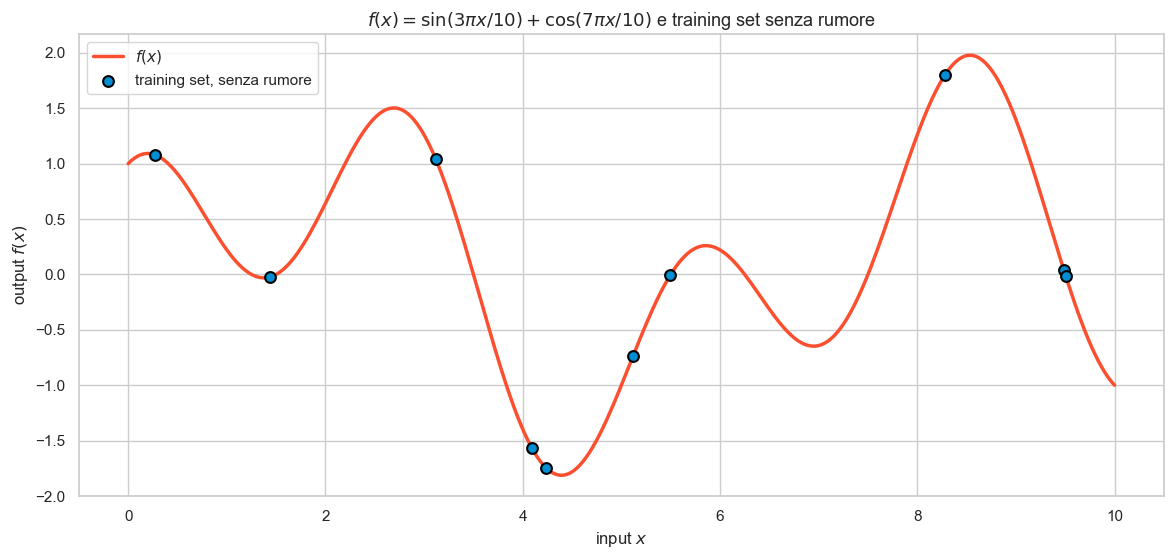

In [38]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(x=x, y=y, color=colors[1], linewidth=2.5, label='$f(x)$', ax=ax)
sns.scatterplot(x=X_train, y=t_n, color=colors[0], s=60, edgecolor='black', linewidth=1.5, zorder=10, label='training set, senza rumore', ax=ax)
ax.set_xlabel('input $x$')
ax.set_ylabel('output $f(x)$')
ax.set_title(r'$f(x) = \sin(3\pi x/10) + \cos(7\pi x/10)$ e training set senza rumore')
plt.show()

Le predizioni sono richieste in un insieme di **punti di test** $\mathbf{Z}=(z_1,\ldots,z_r)$: usiamo tutti i punti della griglia su cui disegniamo le funzioni, in modo da poter rappresentare le funzioni campionate come curve.

In [5]:
X_test = x
n_test = X_test.shape[0]

## La funzione kernel

Come nelle note, assumiamo funzione media nulla, $m(x)=0$: come vi si osserva, è una scelta che non comporta perdita di generalità, perché la media a posteriori dipende dai target e ne apprende livello e andamento. Come kernel usiamo il kernel **RBF** (*squared exponential*)
$$\kappa(x,x') = \sigma_f^2 \exp\left(-\frac{\lVert x - x'\rVert^2}{2\ell^2} \right),$$
dove $\sigma_f^2$ è la **varianza del segnale**, che fissa l'ampiezza tipica delle funzioni, e $\ell$ è la **length scale**, la distanza oltre la quale i valori della funzione diventano praticamente indipendenti. Si noti che $\kappa(x,x)=\sigma_f^2$ è la varianza a priori di $f(x)$ in ogni punto: con la versione del notebook originale, in cui il fattore era $\sigma_f$ e non $\sigma_f^2$, il parametro andava interpretato come una varianza e non come una deviazione standard.

L'implementazione calcola il kernel su tutte le coppie di punti di due insiemi in un'unica operazione vettoriale (`cdist` calcola la matrice delle distanze al quadrato), invece che con un doppio ciclo: con $300$ punti di test le coppie sono $90\,000$.

In [6]:
def kernel(A, B, sigma_f=1., l=1.):
    """Matrice del kernel RBF: K[i,j] = sigma_f^2 exp(-|a_i - b_j|^2 / (2 l^2))."""
    A = np.asarray(A, dtype=float).reshape(len(A), -1)
    B = np.asarray(B, dtype=float).reshape(len(B), -1)
    return sigma_f**2 * np.exp(-cdist(A, B, 'sqeuclidean') / (2*l**2))

l = 1
sigma_f = 1

Il kernel RBF è **stazionario**: dipende solo dalla differenza $x-x'$. Possiamo quindi rappresentarlo come funzione della distanza $x-x'$, al variare degli iperparametri: $\sigma_f$ scala verticalmente la curva, $\ell$ la allarga orizzontalmente.

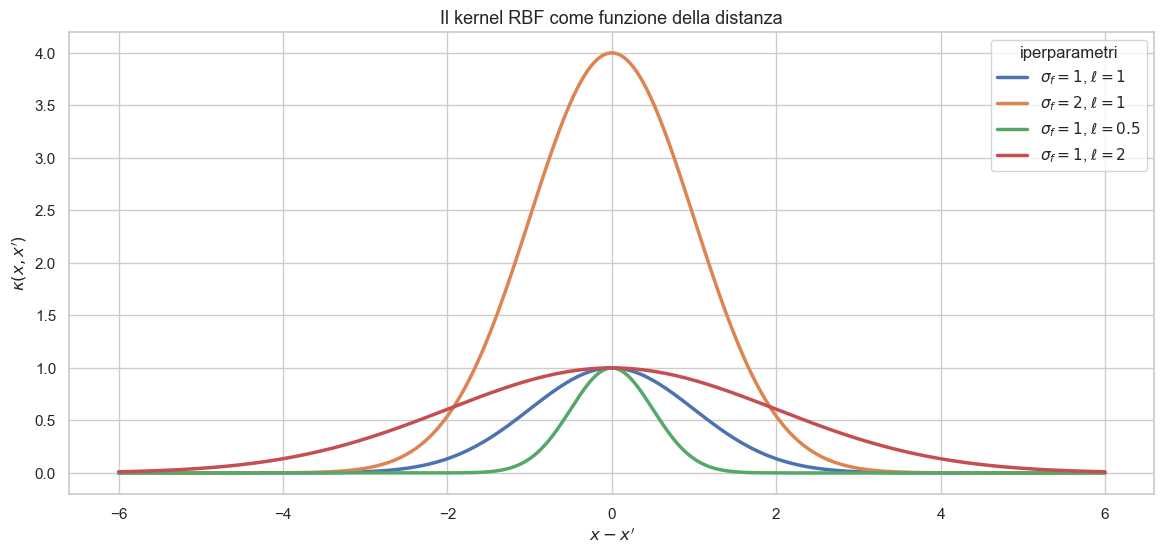

In [7]:
u = np.linspace(-6, 6, 300)
rows = []
for sf, ll in [(1, 1), (2, 1), (1, .5), (1, 2)]:
    rows += [[d, k, r'$\sigma_f={0}$, $\ell={1}$'.format(sf, ll)] for d, k in zip(u, kernel([0.], u, sigma_f=sf, l=ll)[0])]
kd = pd.DataFrame(rows, columns=["$x-x'$", 'kernel', 'iperparametri'])

plt.figure(figsize=(14, 6))
sns.lineplot(data=kd, x="$x-x'$", y='kernel', hue='iperparametri', linewidth=2.5)
plt.ylabel(r"$\kappa(x,x')$")
plt.title('Il kernel RBF come funzione della distanza')
plt.show()

## Le matrici di covarianza

Per la predizione servono tre matrici, che nelle note sono indicate come segue (tra parentesi i nomi usati nel codice):

- $\mathbf{G}_{\mathbf{X}}$ (`K_train`), $n\times n$, con elementi $\kappa(x_i,x_j)$: covarianza tra i valori di $f$ nei punti di training;
- $\mathbf{G}_{\mathbf{Z}}$ (`K_test`), $r\times r$, con elementi $\kappa(z_i,z_j)$: covarianza tra i valori di $f$ nei punti di test;
- $\mathbf{G}_{\mathbf{Z},\mathbf{X}}$ (`K_cross`, che nel codice è memorizzata trasposta, come matrice $n\times r$ con elementi $\kappa(x_i,z_j)$): covarianza incrociata tra punti di training e di test.

Per definizione di processo gaussiano, i valori nei punti di training e di test sono congiuntamente gaussiani, con la matrice di covarianza a blocchi $\mathbf{C}$ che riunisce le tre matrici. Nel caso con rumore, discusso più avanti, la sola modifica è l'aggiunta della varianza del rumore $\sigma_n^2$ sulla diagonale del blocco di training.

In [8]:
def compute_cov_matrices(X_train, X_test, sigma_n=0.1, sigma_f=1, l=1, noise=True):
    """
    Componenti della matrice di covarianza della distribuzione congiunta di training e test:

        [t ]  ~  N(0, [ K_train    K_cross ])
        [f*]          [ K_cross^T  K_test  ]

    K_train = G_X (+ sigma_n^2 I se noise=True), K_test = G_Z, K_cross = G_{Z,X}^T.
    Restituisce (C, K_train, K_test, K_cross).
    """
    K_train = kernel(X_train, X_train, sigma_f=sigma_f, l=l)
    if noise:
        # il rumore riguarda le osservazioni: si aggiunge solo sulla diagonale del blocco di training
        K_train = K_train + sigma_n**2 * np.eye(len(X_train))
    K_test = kernel(X_test, X_test, sigma_f=sigma_f, l=l)
    K_cross = kernel(X_train, X_test, sigma_f=sigma_f, l=l)
    C = np.block([[K_train, K_cross], [K_cross.T, K_test]])
    return C, K_train, K_test, K_cross

Per visualizzare le matrici usiamo una heatmap di seaborn. Con centinaia di righe e colonne, le etichette dei singoli indici sono illeggibili: ne mostriamo solo alcune.

In [9]:
def plot_covariance_matrix(cov, title, xlabel, ylabel, ax=None):
    show = ax is None
    if show:
        fig, ax = plt.subplots(figsize=(9, 7))
    vmin = max(cov.min(), 0)
    sns.heatmap(data=np.clip(cov, vmin, None), cmap='Blues', norm=PowerNorm(gamma=0.5, vmin=vmin, vmax=cov.max()),
                ax=ax, cbar_kws={'label': 'covarianza'}, xticklabels=max(1, cov.shape[1]//10), yticklabels=max(1, cov.shape[0]//10))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if show:
        plt.tight_layout()
        plt.show()

## Osservazioni senza rumore

Assumiamo in questa parte che i valori osservati $\mathbf{t}=(t_1,\ldots,t_n)^T$ nei punti di training $\mathbf{X}=(x_1,\ldots,x_n)^T$ siano esattamente i valori della funzione, $t_i=f(x_i)$. Dati i punti di test $\mathbf{Z}$, la distribuzione congiunta di $\mathbf{t}=f(\mathbf{X})$ e $\mathbf{f}_*=f(\mathbf{Z})$ è
$$
\begin{pmatrix} \mathbf{t} \\ \mathbf{f}_* \end{pmatrix}
\sim\mathcal{N}(\mathbf{0}, \mathbf{C}),\qquad
\mathbf{C} = \begin{pmatrix} \mathbf{G}_{\mathbf{X}} & \mathbf{G}_{\mathbf{Z},\mathbf{X}}^T \\ \mathbf{G}_{\mathbf{Z},\mathbf{X}} & \mathbf{G}_{\mathbf{Z}} \end{pmatrix}.
$$
Calcoliamo le componenti.

In [10]:
C_n, K_train_n, K_test_n, K_cross_n = compute_cov_matrices(X_train, X_test, sigma_f=sigma_f, l=l, noise=False)
print('K_train: {0}, K_test: {1}, K_cross: {2}, C: {3}'.format(K_train_n.shape, K_test_n.shape, K_cross_n.shape, C_n.shape))

K_train: (10, 10), K_test: (300, 300), K_cross: (10, 300), C: (310, 310)


Le quattro matrici rappresentate come heatmap. In $\mathbf{G}_{\mathbf{Z}}$, con i punti di test ordinati lungo l'asse $x$, la covarianza è concentrata in una banda attorno alla diagonale, di larghezza proporzionale a $\ell$: punti vicini hanno valori fortemente correlati, punti lontani quasi indipendenti. $\mathbf{G}_{\mathbf{X}}$ è piccola ($10\times 10$) e quasi diagonale, perché i punti di training sono in genere più distanti tra loro di $\ell$. La covarianza incrociata mostra, per ogni punto di training (riga), la regione dei punti di test (colonne) su cui esso porta informazione.

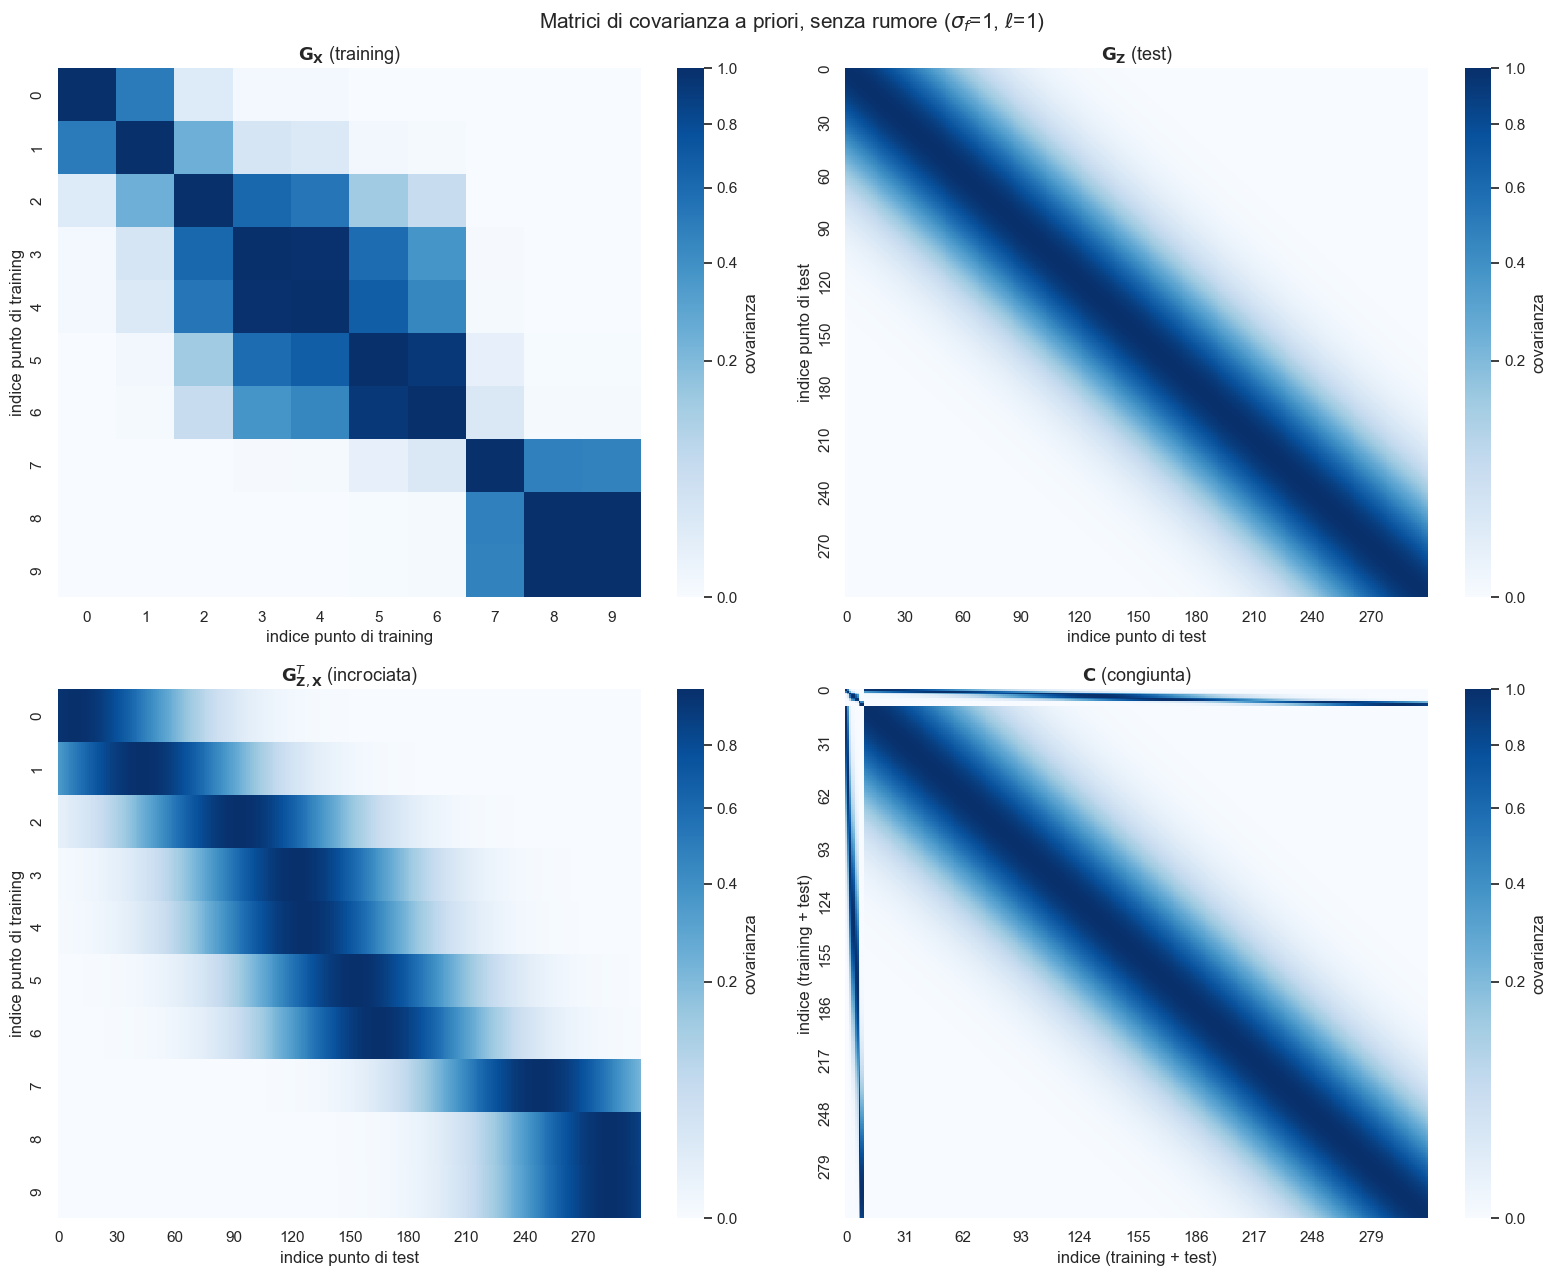

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
plot_covariance_matrix(K_train_n, r'$\mathbf{G}_{\mathbf{X}}$ (training)', 'indice punto di training', 'indice punto di training', ax=axes[0,0])
plot_covariance_matrix(K_test_n, r'$\mathbf{G}_{\mathbf{Z}}$ (test)', 'indice punto di test', 'indice punto di test', ax=axes[0,1])
plot_covariance_matrix(K_cross_n, r'$\mathbf{G}_{\mathbf{Z},\mathbf{X}}^T$ (incrociata)', 'indice punto di test', 'indice punto di training', ax=axes[1,0])
plot_covariance_matrix(C_n, r'$\mathbf{C}$ (congiunta)', 'indice (training + test)', 'indice (training + test)', ax=axes[1,1])
plt.suptitle(r'Matrici di covarianza a priori, senza rumore ($\sigma_f$={0}, $\ell$={1})'.format(sigma_f, l), fontsize=15)
plt.tight_layout()
plt.show()

### Distribuzione a priori

Prima di osservare i dati, la distribuzione dei valori nei punti di test è
$$p_{prior}(\mathbf{f}_*)=\mathcal{N}(\mathbf{f}_*;\mathbf{0}, \mathbf{G}_{\mathbf{Z}}).$$
Campionare da questa gaussiana dà un valore per ogni punto di $\mathbf{Z}$, che, con una griglia fitta, possiamo disegnare come una curva: è un campione di funzione dal processo, rappresentato sulla griglia.

Per generare i campioni usiamo la **fattorizzazione di Cholesky** $\mathbf{G}_{\mathbf{Z}}=\mathbf{L}\mathbf{L}^T$: se $\mathbf{u}\sim\mathcal{N}(\mathbf{0},\mathbf{I})$, allora $\mathbf{L}\mathbf{u}\sim\mathcal{N}(\mathbf{0},\mathbf{G}_{\mathbf{Z}})$. Per punti molto vicini $\mathbf{G}_{\mathbf{Z}}$ è numericamente singolare (righe quasi uguali), e aggiungiamo sulla diagonale un piccolo termine di regolarizzazione (*jitter*), che non ha alcun effetto visibile sui campioni.

In [41]:
def sample_gaussian(mean, cov, n_samples, jitter=1e-8):
    """Campioni da N(mean, cov) mediante la fattorizzazione di Cholesky."""
    L = np.linalg.cholesky(cov + jitter*np.eye(len(mean)))
    return mean + (L @ rng.standard_normal((len(mean), n_samples))).T

def plot_samples(samples, title, X_obs=None, t_obs=None, ax=None, band=None):
    """Disegna funzioni campionate (sulla griglia X_test), la funzione vera e, se presenti, le osservazioni."""
    show = ax is None
    if show:
        fig, ax = plt.subplots(figsize=(14, 6))
    if band is not None:
        ax.fill_between(X_test, band[0], band[1], color=colors[0], alpha=.15)
    for i, s in enumerate(samples):
        sns.lineplot(x=X_test, y=s, color=colors[0], alpha=.35, linewidth=1.3, ax=ax, label='campioni' if i == 0 else None)
    sns.lineplot(x=x, y=y, color=colors[1], linewidth=2.5, label='$f(x)$', ax=ax)
    if X_obs is not None:
        sns.scatterplot(x=X_obs, y=t_obs, color=colors[7], s=60, edgecolor='black', linewidth=1.5, zorder=10, label='osservazioni', ax=ax)
    ax.set_xlabel('input $x$')
    ax.set_ylabel('output')
    ax.set_title(title)
    ax.legend(loc='lower right')
    if show:
        plt.show()

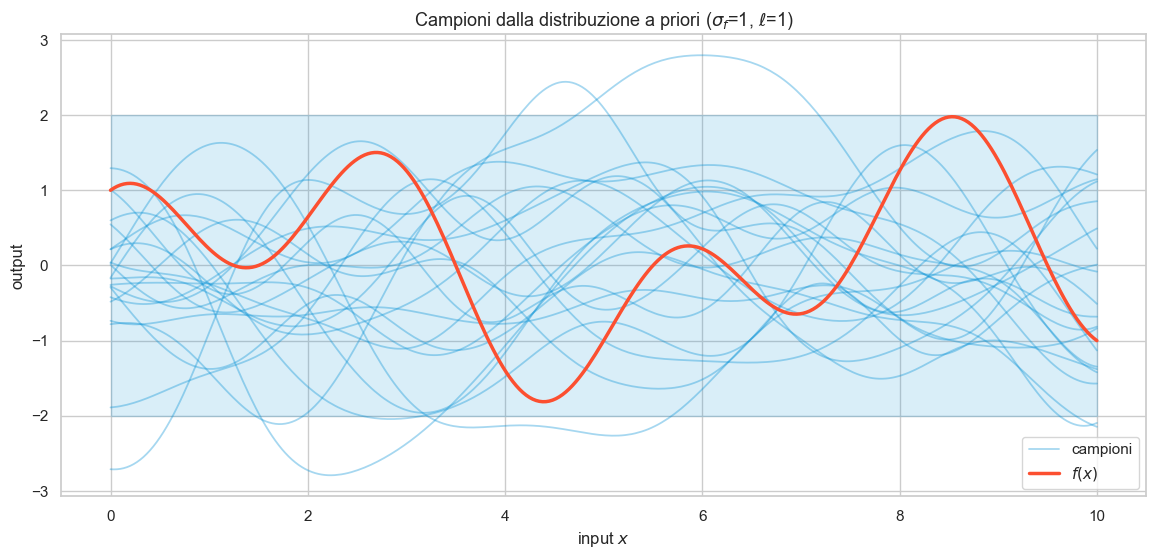

In [13]:
prior_samples = sample_gaussian(np.zeros(n_test), K_test_n, 20)
plot_samples(prior_samples, r'Campioni dalla distribuzione a priori ($\sigma_f$={0}, $\ell$={1})'.format(sigma_f, l),
             band=(-2*sigma_f*np.ones(n_test), 2*sigma_f*np.ones(n_test)))

I campioni sono funzioni lisce, con valori tipicamente in $[-2\sigma_f,2\sigma_f]$ (la banda) e oscillazioni su una scala dell'ordine di $\ell$. La funzione vera è una tra le tante compatibili con il prior: la sua ampiezza e la sua scala di variazione sono simili a quelle dei campioni, il che indica che gli iperparametri scelti sono ragionevoli.

### Distribuzione a posteriori

Condizionando la distribuzione congiunta sulle osservazioni $\mathbf{t}$, con la formula del condizionamento gaussiano richiamata nelle note, la distribuzione a posteriori dei valori nei punti di test è
$$p_{post}(\mathbf{f}_*)=\mathcal{N}(\mathbf{f}_*;\boldsymbol\mu_p, \boldsymbol\Sigma_p),$$
con
$$\boldsymbol\mu_p=\mathbf{G}_{\mathbf{Z},\mathbf{X}}\mathbf{G}_{\mathbf{X}}^{-1}\mathbf{t},\qquad \boldsymbol\Sigma_p=\mathbf{G}_{\mathbf{Z}}-\mathbf{G}_{\mathbf{Z},\mathbf{X}}\mathbf{G}_{\mathbf{X}}^{-1}\mathbf{G}_{\mathbf{Z},\mathbf{X}}^T.$$

**Implementazione.** Calcolare esplicitamente l'inversa $\mathbf{G}_{\mathbf{X}}^{-1}$, come nel notebook originale, è costoso e numericamente instabile: la matrice è spesso mal condizionata, in particolare senza rumore e con punti vicini. Si usa invece la fattorizzazione di Cholesky $\mathbf{G}_{\mathbf{X}}=\mathbf{L}\mathbf{L}^T$, con $\mathbf{L}$ triangolare inferiore, e si risolvono sistemi triangolari:
$$\boldsymbol\alpha=\mathbf{L}^{-T}\mathbf{L}^{-1}\mathbf{t},\quad \boldsymbol\mu_p=\mathbf{G}_{\mathbf{Z},\mathbf{X}}\boldsymbol\alpha,\qquad \mathbf{V}=\mathbf{L}^{-1}\mathbf{G}_{\mathbf{Z},\mathbf{X}}^T,\quad \boldsymbol\Sigma_p=\mathbf{G}_{\mathbf{Z}}-\mathbf{V}^T\mathbf{V}.$$
La fattorizzazione costa $O(n^3)$ e va calcolata una sola volta; ogni sistema triangolare costa $O(n^2)$. La stessa fattorizzazione dà anche il determinante, $\log|\mathbf{G}_{\mathbf{X}}|=2\sum_i\log L_{ii}$, che servirà per la verosimiglianza marginale. Anche qui aggiungiamo un piccolo jitter sulla diagonale nel caso senza rumore.

In [14]:
def compute_posterior_parameters(K_train, K_test, K_cross, t, jitter=1e-10):
    """
    Media e covarianza a posteriori nei punti di test:
        mu_p    = K_cross^T K_train^{-1} t
        Sigma_p = K_test - K_cross^T K_train^{-1} K_cross
    calcolate con la fattorizzazione di Cholesky di K_train, senza invertire matrici.
    """
    L = cholesky(K_train + jitter*np.eye(len(t)), lower=True)
    alpha = solve_triangular(L.T, solve_triangular(L, t, lower=True), lower=False)
    means = K_cross.T @ alpha
    V = solve_triangular(L, K_cross, lower=True)
    covs = K_test - V.T @ V
    return means, covs

In [15]:
mean_n, cov_n = compute_posterior_parameters(K_train_n, K_test_n, K_cross_n, t_n)

La media a posteriori approssima la funzione vera, e coincide con essa nei punti di training: come osservato nelle note, in assenza di rumore il processo **interpola** i dati. Lontano dai punti di training, invece, la media torna verso la media a priori, $0$: è ciò che si vede, ad esempio, nelle regioni senza osservazioni.

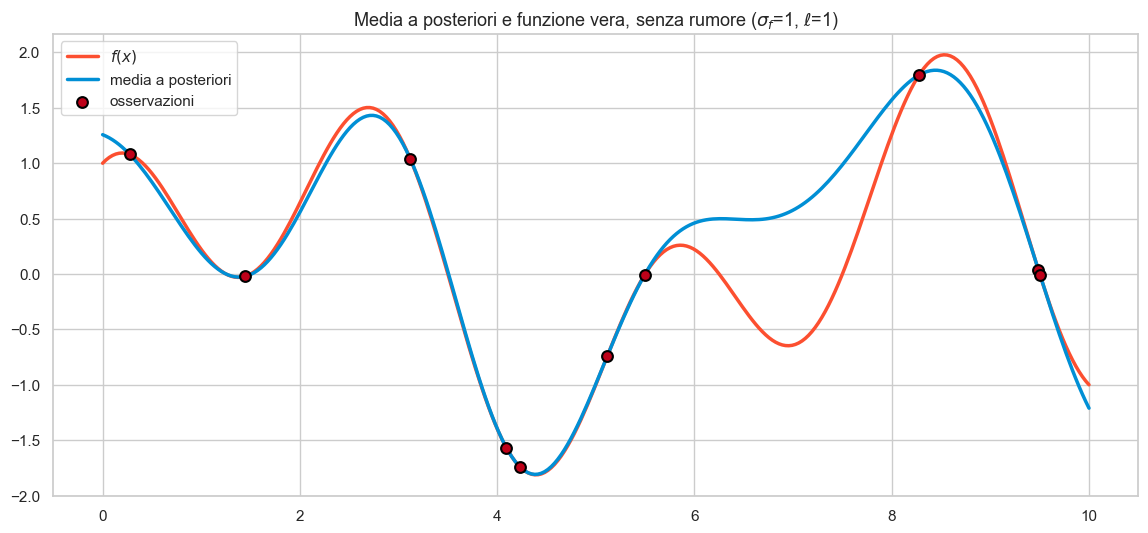

In [39]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(x=x, y=f(x), color=colors[1], linewidth=2.5, label='$f(x)$', ax=ax)
sns.lineplot(x=X_test, y=mean_n, color=colors[0], linewidth=2.5, label='media a posteriori', ax=ax)
sns.scatterplot(x=X_train, y=t_n, color=colors[7], s=60, edgecolor='black', linewidth=1.5, zorder=10, label='osservazioni', ax=ax)
ax.set_title(r'Media a posteriori e funzione vera, senza rumore ($\sigma_f$={0}, $\ell$={1})'.format(sigma_f, l))
plt.show()

**La media come combinazione lineare dei target.** Per un punto di test $z$, $\mu_p(z)=\mathbf{g}_z^T\mathbf{G}_{\mathbf{X}}^{-1}\mathbf{t}=\sum_i w_i(z)\,t_i$, con pesi $\mathbf{w}(z)=\mathbf{G}_{\mathbf{X}}^{-1}\mathbf{g}_z$ che non dipendono dai target. Come osservato nelle note, i pesi svolgono il ruolo del **kernel equivalente** della regressione lineare bayesiana. Il grafico mostra, per tre punti di training, il peso $w_i(z)$ in funzione di $z$: vale $1$ nel punto $x_i$ e $0$ negli altri punti di training (è la condizione di interpolazione) ed è grande nella regione attorno a $x_i$, ma non è un semplice "bump" come il kernel di Nadaraya–Watson: può superare $1$, assumere valori negativi e non essere trascurabile anche lontano da $x_i$, nelle regioni prive di dati. Ad esempio, tra $5.5$ e $8.3$, dove non ci sono osservazioni, la predizione dipende in parte anche dal target in $x_2$, e non solo dai due punti di training più vicini: i pesi dipendono dalla configurazione di tutti i punti di training, non solo dalla distanza tra $z$ e $x_i$.

Si noti che i pesi non sono sempre così regolari: due punti di training molto vicini, come i due attorno a $x=9.5$, hanno colonne quasi uguali in $\mathbf{G}_{\mathbf{X}}$, che è quindi mal condizionata, e i loro pesi assumono valori molto grandi di segno opposto, che si compensano. È un altro sintomo del fatto che, senza rumore, imporre l'interpolazione esatta di punti vicini è un problema numericamente delicato.

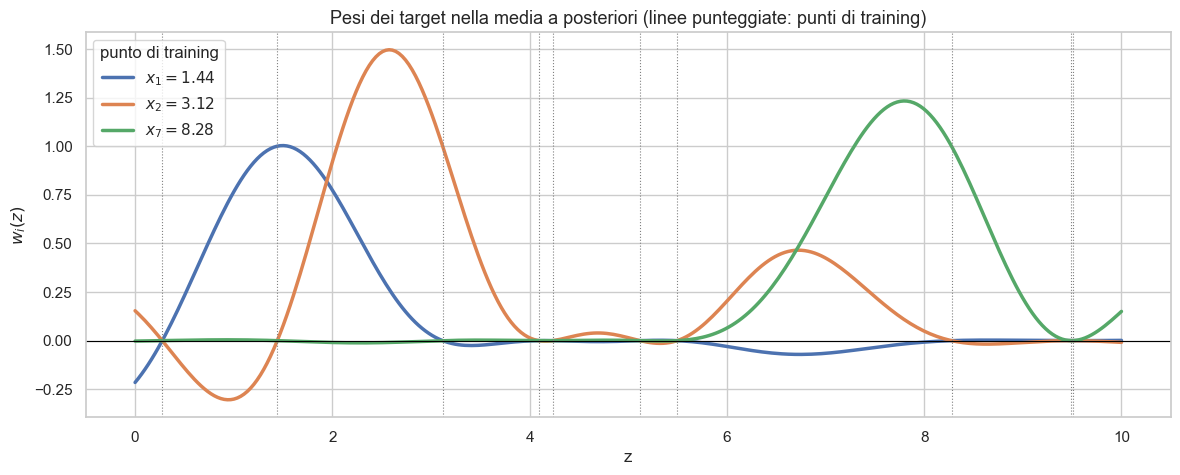

In [17]:
W = np.linalg.solve(K_train_n + 1e-10*np.eye(n_train), K_cross_n)   # riga i: peso w_i(z) per tutti gli z di test
rows = []
for i in (1, 2, 7):
    rows += [[z, w, '$x_{{{0}}}={1:.2f}$'.format(i, X_train[i])] for z, w in zip(X_test, W[i])]
wd = pd.DataFrame(rows, columns=['z', 'peso', 'punto di training'])

fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=wd, x='z', y='peso', hue='punto di training', linewidth=2.5, ax=ax)
for xi in X_train:
    ax.axvline(xi, color='grey', lw=.8, ls=':')
ax.axhline(0, color='black', lw=.8)
ax.set_ylabel(r'$w_i(z)$')
ax.set_title(r'Pesi dei target nella media a posteriori (linee punteggiate: punti di training)')
plt.show()

La covarianza a posteriori è la covarianza a priori diminuita di una matrice semidefinita positiva: osservare i dati può solo ridurre l'incertezza. Nella heatmap si vedono "buchi" in corrispondenza dei punti di training: in assenza di rumore la varianza a posteriori in quei punti è nulla, e lo è anche la covarianza con qualunque altro punto, perché il valore di $f$ è noto con certezza.

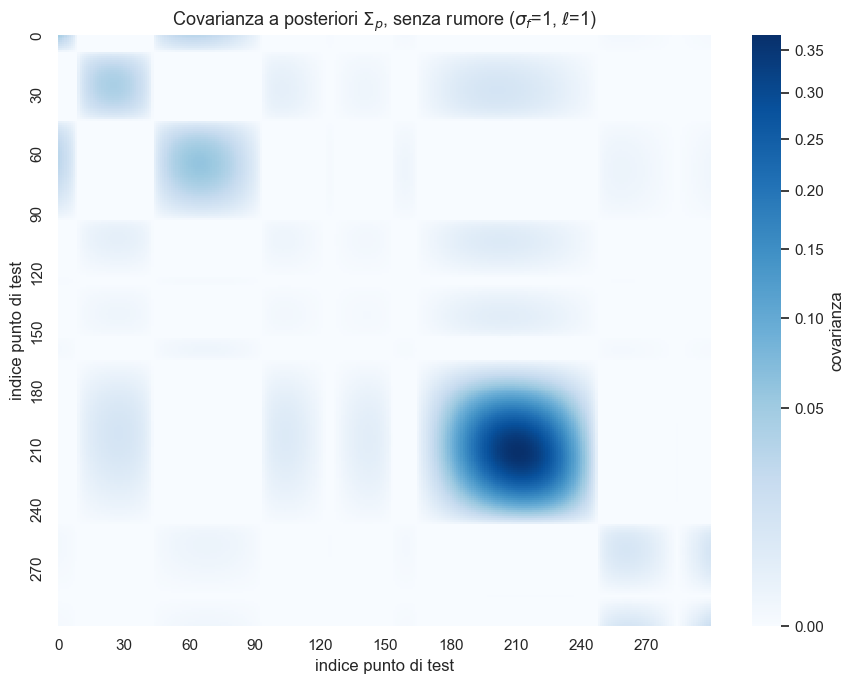

In [18]:
plot_covariance_matrix(cov_n, r'Covarianza a posteriori $\Sigma_p$, senza rumore ($\sigma_f$={0}, $\ell$={1})'.format(sigma_f, l),
                       'indice punto di test', 'indice punto di test')

Campioni dalla distribuzione a posteriori $p_{post}(\mathbf{f}_*)$: tutte le funzioni campionate passano per le osservazioni, e si discostano tra loro solo tra un'osservazione e l'altra e al di fuori dell'intervallo coperto dai dati.

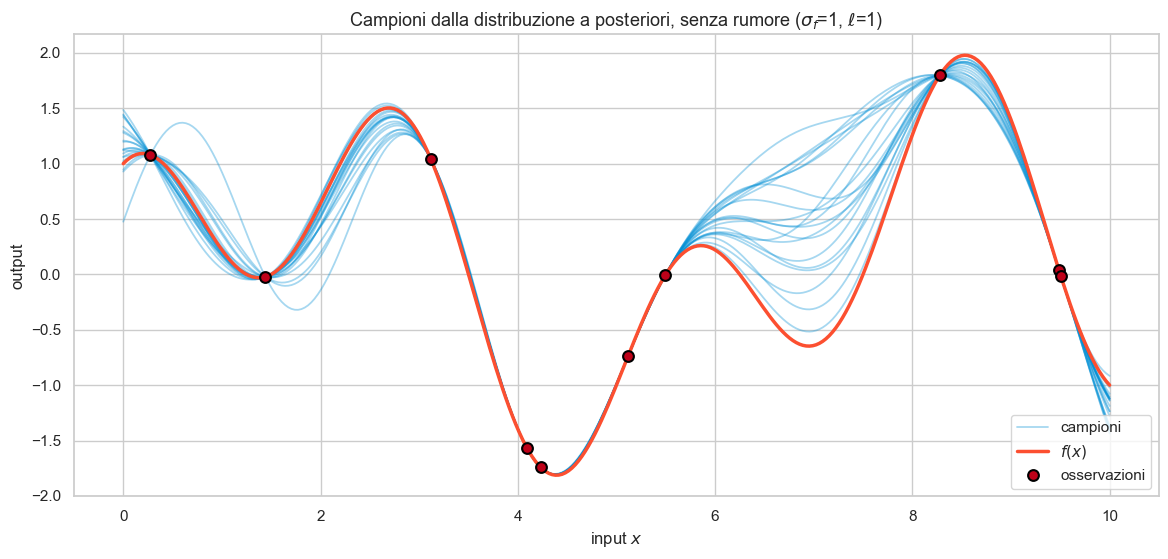

In [42]:
post_samples = sample_gaussian(mean_n, cov_n, 20)
plot_samples(post_samples, r'Campioni dalla distribuzione a posteriori, senza rumore ($\sigma_f$={0}, $\ell$={1})'.format(sigma_f, l), X_train, t_n)

### Distribuzione predittiva

Per ogni punto di test $z$ la distribuzione predittiva è la marginale di $p_{post}$ in $z$, una gaussiana con media $\mu_p(z)$ e varianza $\sigma_p^2(z)=[\boldsymbol\Sigma_p]_{zz}$, l'elemento corrispondente sulla diagonale della covarianza a posteriori. Rappresentiamo la media e una banda di $\pm 2$ **deviazioni standard**, che contiene circa il $95\%$ della probabilità. (Nel notebook originale la banda era calcolata come media $\pm$ *varianza*, che non ha le unità di misura corrette e sottostima l'incertezza dove la varianza è minore di $1$.)

Quando le osservazioni sono rumorose distinguiamo due predizioni: quella del valore della funzione, $f(z)$, con varianza $\sigma_p^2(z)$, e quella di una nuova osservazione $t_*=f(z)+\varepsilon$, che ha varianza $\sigma_p^2(z)+\sigma_n^2$. La funzione `predict` restituisce la prima, o la seconda se `observation=True`.

In [43]:
def predict(X_test, X_train, t, sigma_f=1, l=1, sigma_n=0.1, noise=False, observation=False):
    """Media e deviazione standard della distribuzione predittiva nei punti di test."""
    C, K_train, K_test, K_cross = compute_cov_matrices(X_train, X_test, sigma_f=sigma_f, l=l, sigma_n=sigma_n, noise=noise)
    m, c = compute_posterior_parameters(K_train, K_test, K_cross, t)
    var = np.clip(np.diag(c), 0, None)
    if noise and observation:
        var = var + sigma_n**2
    return m, np.sqrt(var)

def plot_predictive(X_test, X_train, t, title, ax=None, **kw):
    show = ax is None
    if show:
        fig, ax = plt.subplots(figsize=(14, 6))
    means, sd = predict(X_test, X_train, t, **kw)
    ax.fill_between(X_test, means - 2*sd, means + 2*sd, color=colors[0], alpha=0.25, label=r'media $\pm 2\sigma$')
    sns.lineplot(x=X_test, y=means, color=colors[0], linewidth=2.5, label='media predittiva', ax=ax)
    sns.lineplot(x=x, y=y, color=colors[1], linewidth=2.5, label='$f(x)$', ax=ax)
    sns.scatterplot(x=X_train, y=t, color=colors[4], s=60, edgecolor='black', linewidth=1.5, zorder=10, label='osservazioni', ax=ax)
    ax.set_title(title)
    ax.set_xlabel('input $x$')
    ax.legend(loc='lower right')
    if show:
        plt.show()

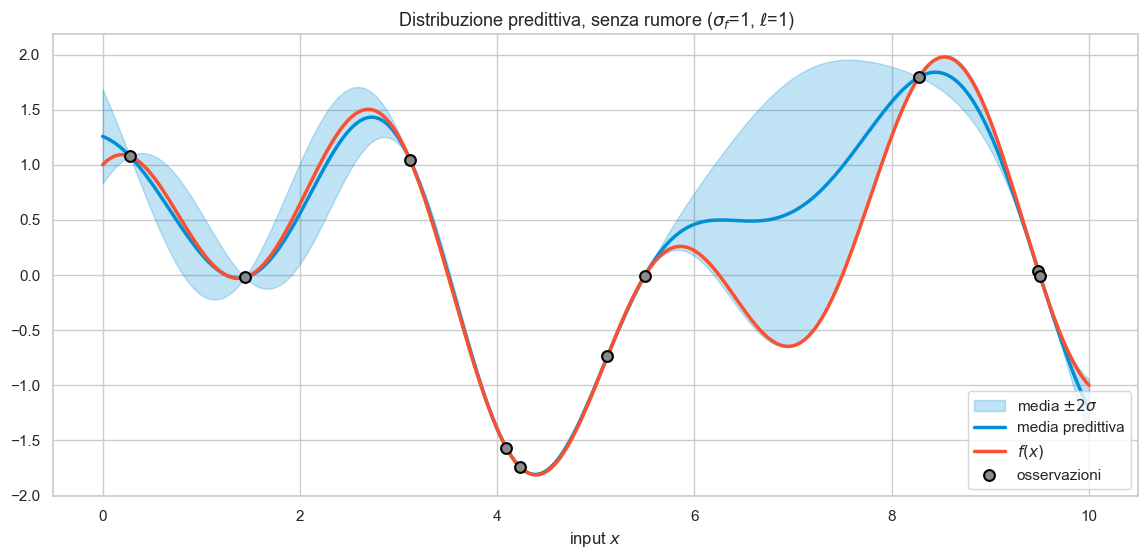

In [44]:
plot_predictive(X_test, X_train, t_n, r'Distribuzione predittiva, senza rumore ($\sigma_f$={0}, $\ell$={1})'.format(sigma_f, l),
                sigma_f=sigma_f, l=l, noise=False)

La banda si annulla nei punti di training e si allarga tra di essi, tanto più quanto più sono distanti; al di fuori dell'intervallo dei dati tende a $\pm2\sigma_f$, l'incertezza a priori. La funzione vera resta quasi ovunque all'interno della banda: l'incertezza stimata è **calibrata**, perché la funzione è compatibile con le ipotesi del prior.

## Osservazioni con rumore gaussiano

Più realisticamente, assumiamo che ogni osservazione sia affetta da rumore gaussiano additivo indipendente, $t_i=f(x_i)+\varepsilon_i$, $\varepsilon_i\sim\mathcal{N}(0,\sigma_n^2)$, come nel modello probabilistico della regressione lineare. La distribuzione congiunta di $\mathbf{t}$ e $\mathbf{f}_*$ diventa
$$
\begin{pmatrix} \mathbf{t} \\ \mathbf{f}_* \end{pmatrix}\sim\mathcal{N}(\mathbf{0}, \mathbf{C}),\qquad
\mathbf{C} = \begin{pmatrix} \hat{\boldsymbol\Sigma}_{\mathbf{X}} & \mathbf{G}_{\mathbf{Z},\mathbf{X}}^T \\ \mathbf{G}_{\mathbf{Z},\mathbf{X}} & \mathbf{G}_{\mathbf{Z}} \end{pmatrix},\qquad \hat{\boldsymbol\Sigma}_{\mathbf{X}}=\mathbf{G}_{\mathbf{X}}+\sigma_n^2\mathbf{I}.
$$
L'unica modifica è il termine $\sigma_n^2\mathbf{I}$ nel blocco di training: il rumore è indipendente tra le osservazioni (quindi solo sulla diagonale) e dalla funzione (quindi non modifica la covarianza incrociata), e riguarda le osservazioni, non i valori di $f$ nei punti di test.

Generiamo le osservazioni rumorose:

In [22]:
# deviazione standard del rumore
sigma_n = 0.2
epsilon = rng.normal(loc=0, scale=sigma_n, size=n_train)
t_g = t_n + epsilon

Con solo $10$ valori, l'istogramma degli errori dà un'idea molto approssimativa della distribuzione gaussiana da cui sono generati (in rosso la densità vera):

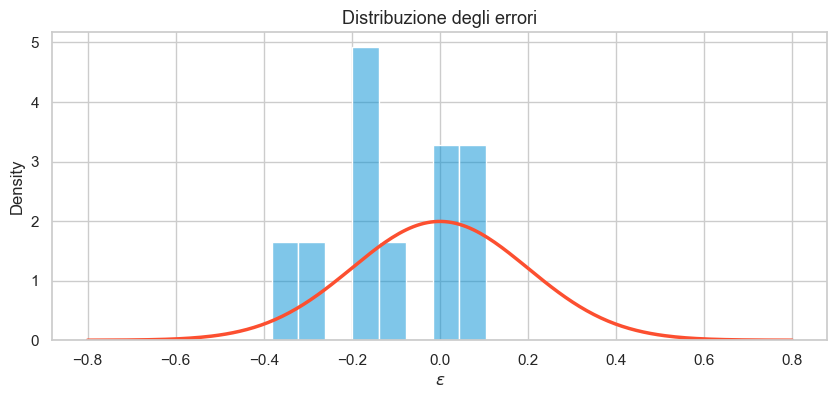

In [23]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(epsilon, stat='density', bins=8, color=colors[0], alpha=.5, ax=ax)
e = np.linspace(-4*sigma_n, 4*sigma_n, 200)
sns.lineplot(x=e, y=np.exp(-e**2/(2*sigma_n**2))/np.sqrt(2*np.pi*sigma_n**2), color=colors[1], linewidth=2.5, ax=ax)
ax.set(title='Distribuzione degli errori', xlabel=r'$\varepsilon$');
plt.show()

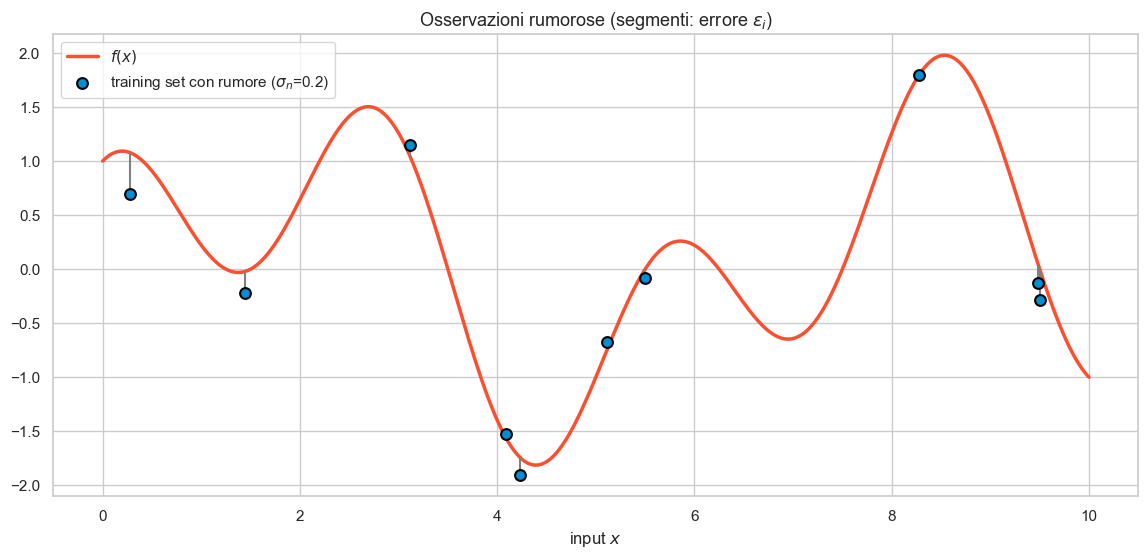

In [45]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(x=x, y=y, color=colors[1], linewidth=2.5, label='$f(x)$', ax=ax)
ax.vlines(X_train, t_n, t_g, color='grey', lw=1.5)
sns.scatterplot(x=X_train, y=t_g, color=colors[0], s=60, edgecolor='black', linewidth=1.5, zorder=10, label=r'training set con rumore ($\sigma_n$={0})'.format(sigma_n), ax=ax)
ax.set_xlabel('input $x$')
ax.set_title('Osservazioni rumorose (segmenti: errore $\\varepsilon_i$)')
plt.show()

In [25]:
C_g, K_train_g, K_test_g, K_cross_g = compute_cov_matrices(X_train, X_test, sigma_f=sigma_f, sigma_n=sigma_n, l=l, noise=True)
print('Diagonale di K_train senza rumore: {0}'.format(np.round(np.diag(K_train_n)[:4], 3)))
print('Diagonale di K_train con rumore:   {0}'.format(np.round(np.diag(K_train_g)[:4], 3)))
print('K_test e K_cross invariati: {0}, {1}'.format(np.allclose(K_test_g, K_test_n), np.allclose(K_cross_g, K_cross_n)))

Diagonale di K_train senza rumore: [1. 1. 1. 1.]
Diagonale di K_train con rumore:   [1.04 1.04 1.04 1.04]
K_test e K_cross invariati: True, True


Rispetto al caso senza rumore cambia solo la diagonale di $\mathbf{G}_{\mathbf{X}}$, che passa da $\sigma_f^2$ a $\sigma_f^2+\sigma_n^2$; le altre matrici, e quindi anche la distribuzione a priori dei valori di $f$ nei punti di test, sono identiche.

La distribuzione a posteriori è data dalle stesse formule, con $\hat{\boldsymbol\Sigma}_{\mathbf{X}}$ al posto di $\mathbf{G}_{\mathbf{X}}$:
$$\boldsymbol\mu_p=\mathbf{G}_{\mathbf{Z},\mathbf{X}}\hat{\boldsymbol\Sigma}_{\mathbf{X}}^{-1}\mathbf{t},\qquad \boldsymbol\Sigma_p=\mathbf{G}_{\mathbf{Z}}-\mathbf{G}_{\mathbf{Z},\mathbf{X}}\hat{\boldsymbol\Sigma}_{\mathbf{X}}^{-1}\mathbf{G}_{\mathbf{Z},\mathbf{X}}^T.$$
Il termine $\sigma_n^2\mathbf{I}$ rende la matrice da invertire "più grande", e le correzioni rispetto al prior più piccole: la media non è più costretta a passare per le osservazioni, e la varianza nei punti di training non si annulla. Come visto nelle note, il processo **liscia** i dati invece di interpolarli.

In [26]:
mean_g, cov_g = compute_posterior_parameters(K_train_g, K_test_g, K_cross_g, t_g)

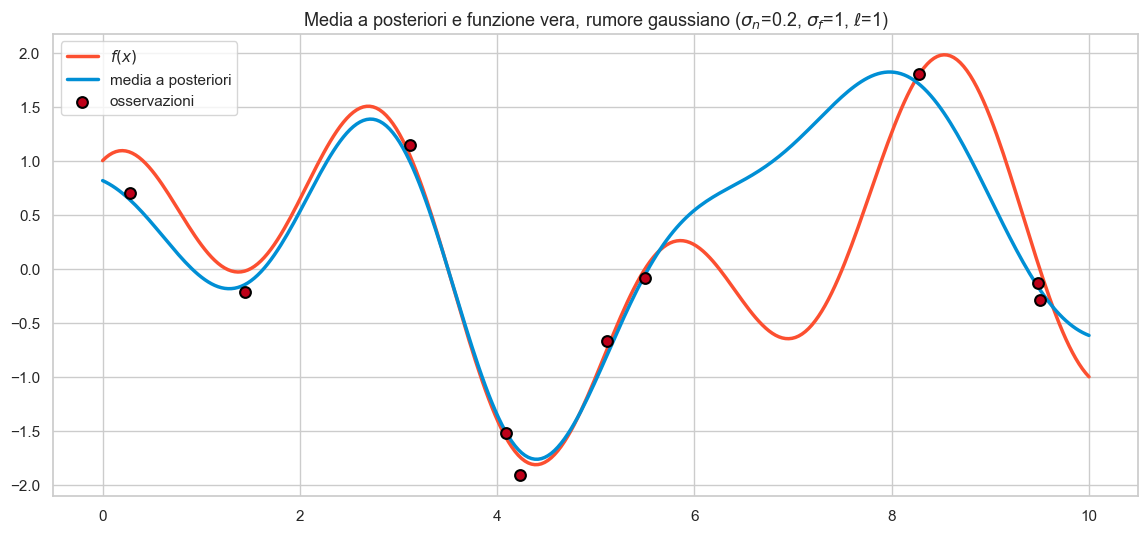

In [46]:
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(x=x, y=y, color=colors[1], linewidth=2.5, label='$f(x)$', ax=ax)
sns.lineplot(x=X_test, y=mean_g, color=colors[0], linewidth=2.5, label='media a posteriori', ax=ax)
sns.scatterplot(x=X_train, y=t_g, color=colors[7], s=60, edgecolor='black', linewidth=1.5, zorder=10, label='osservazioni', ax=ax)
ax.set_title(r'Media a posteriori e funzione vera, rumore gaussiano ($\sigma_n$={0}, $\sigma_f$={1}, $\ell$={2})'.format(sigma_n, sigma_f, l))
plt.show()

La covarianza a posteriori non ha più "buchi" in corrispondenza dei punti di training, ma solo zone di varianza ridotta:

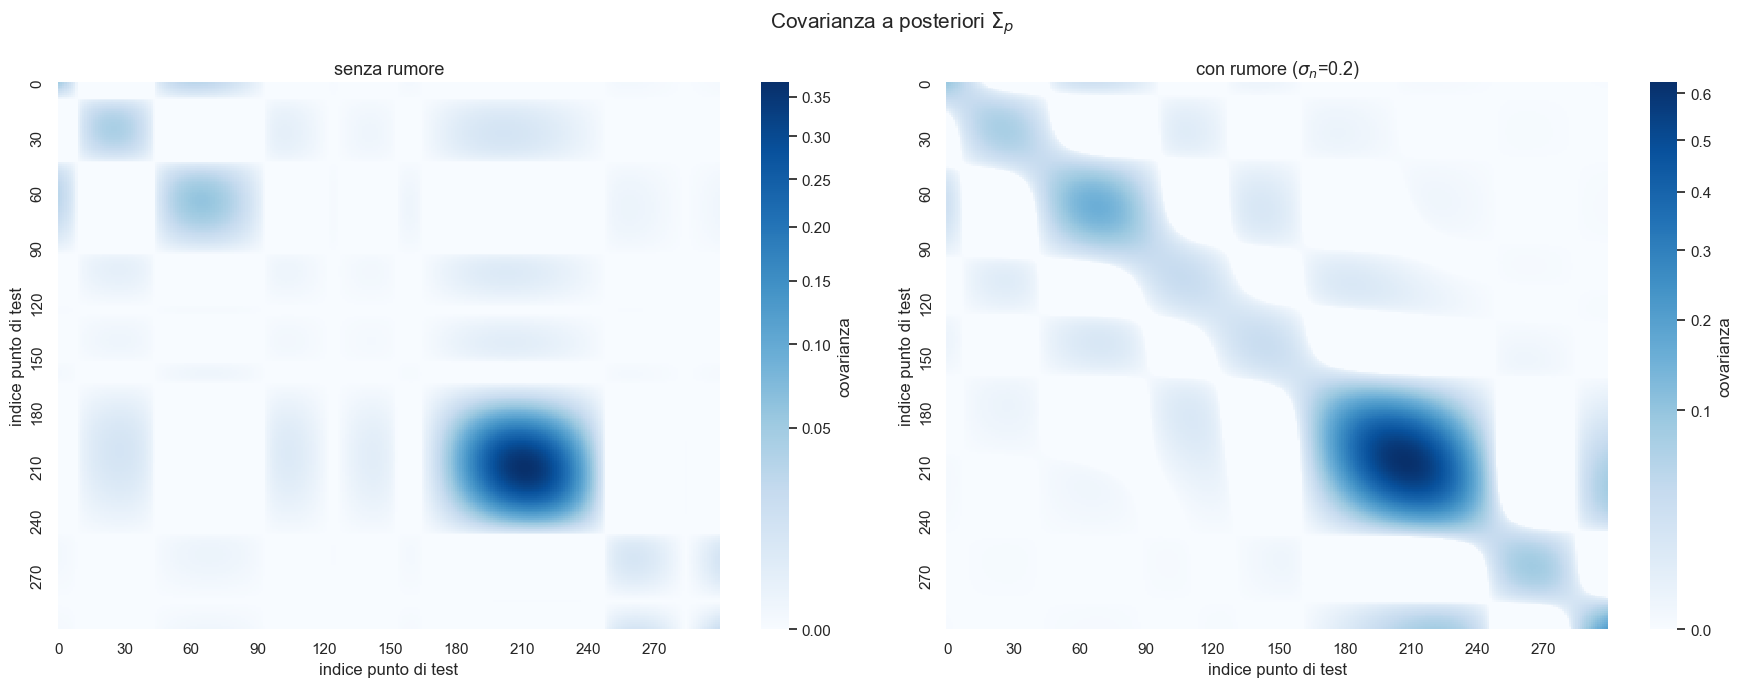

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
plot_covariance_matrix(cov_n, 'senza rumore', 'indice punto di test', 'indice punto di test', ax=axes[0])
plot_covariance_matrix(cov_g, r'con rumore ($\sigma_n$={0})'.format(sigma_n), 'indice punto di test', 'indice punto di test', ax=axes[1])
plt.suptitle(r'Covarianza a posteriori $\Sigma_p$', fontsize=15)
plt.tight_layout()
plt.show()

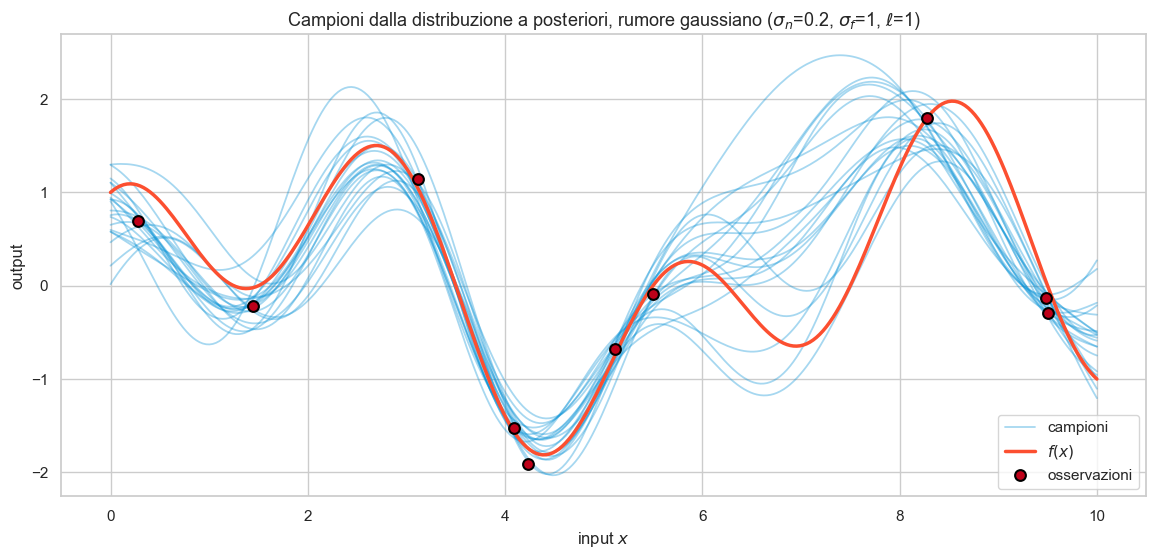

In [47]:
plot_samples(sample_gaussian(mean_g, cov_g, 20), r'Campioni dalla distribuzione a posteriori, rumore gaussiano ($\sigma_n$={0}, $\sigma_f$={1}, $\ell$={2})'.format(sigma_n, sigma_f, l), X_train, t_g)

Confrontiamo infine la distribuzione predittiva del valore della funzione, $f(z)$, con quella di una nuova osservazione, $t_*$: la seconda include anche il rumore, e la sua banda è più larga di $2\sigma_n$ anche dove la funzione è ben determinata dai dati. È la distinzione, vista nelle note sulla regressione lineare, tra incertezza **epistemica** (sui valori di $f$, che si riduce con i dati) e **aleatoria** (il rumore, che resta comunque).

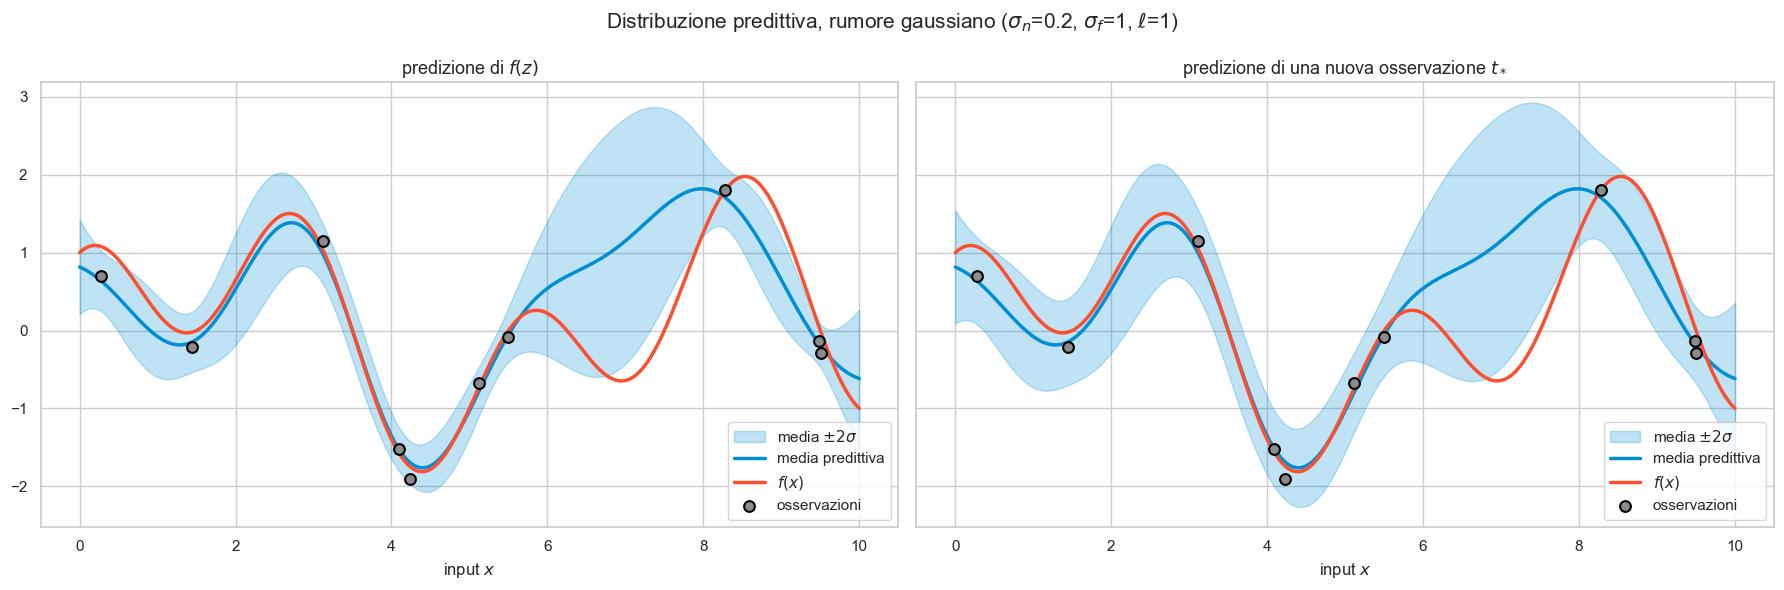

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)
plot_predictive(X_test, X_train, t_g, r'predizione di $f(z)$', ax=axes[0], sigma_f=sigma_f, l=l, sigma_n=sigma_n, noise=True)
plot_predictive(X_test, X_train, t_g, r'predizione di una nuova osservazione $t_*$', ax=axes[1], sigma_f=sigma_f, l=l, sigma_n=sigma_n, noise=True, observation=True)
plt.suptitle(r'Distribuzione predittiva, rumore gaussiano ($\sigma_n$={0}, $\sigma_f$={1}, $\ell$={2})'.format(sigma_n, sigma_f, l), fontsize=15)
plt.tight_layout()
plt.show()

## Effetto degli iperparametri

Studiamo ora l'effetto degli iperparametri $\sigma_f$ e $\ell$ del kernel, nel caso senza rumore:

- $\sigma_f$ descrive l'**ampiezza** delle funzioni: fissa la varianza a priori in ogni punto, e quindi la larghezza della banda di incertezza lontano dai dati;
- $\ell$ è un parametro di **località**: la distanza entro cui i punti interagiscono, e quindi la scala su cui le funzioni variano e la distanza fino a cui un'osservazione influenza la predizione.

Invece di ripetere lo stesso codice in molte celle, come nel notebook originale, confrontiamo le distribuzioni a posteriori per diverse combinazioni di valori in un'unica figura. Le prime due righe variano un solo iperparametro alla volta rispetto al caso base $\sigma_f=1$, $\ell=1$.

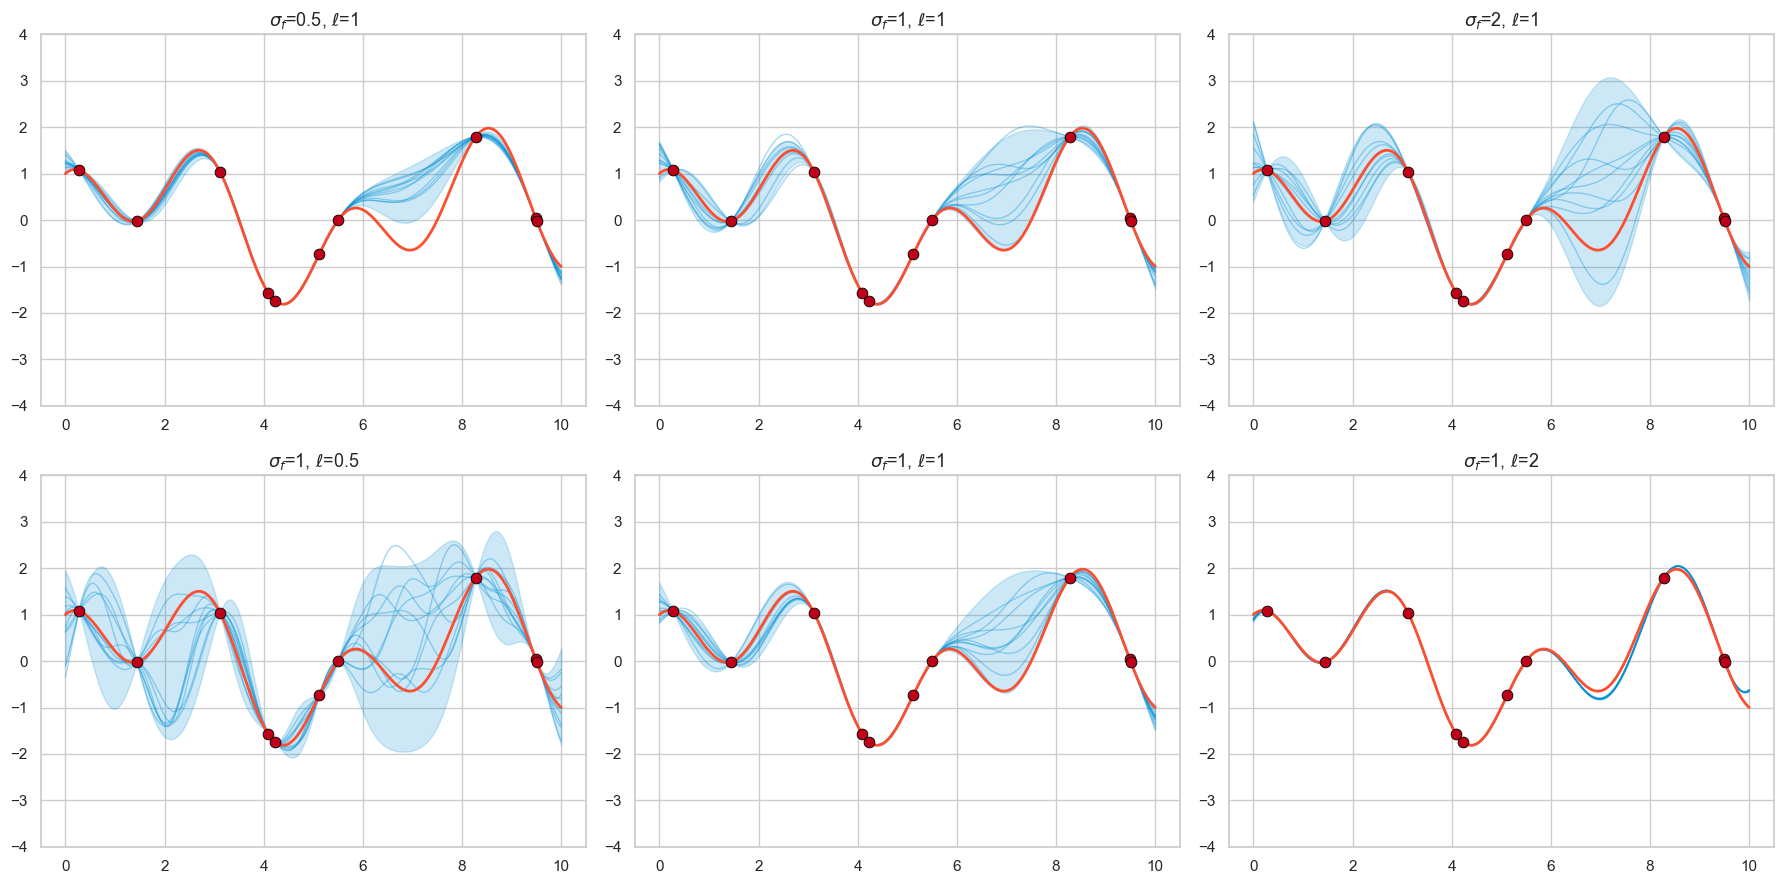

In [49]:
def plot_posterior_grid(params, ncols=3, n_samples=10):
    nrows = int(np.ceil(len(params)/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 4.5*nrows), squeeze=False)
    for ax, (sf, ll) in zip(axes.ravel(), params):
        _, K_tr, K_te, K_cr = compute_cov_matrices(X_train, X_test, sigma_f=sf, l=ll, noise=False)
        m, c = compute_posterior_parameters(K_tr, K_te, K_cr, t_n)
        sd = np.sqrt(np.clip(np.diag(c), 0, None))
        ax.fill_between(X_test, m-2*sd, m+2*sd, color=colors[0], alpha=.2)
        for s in sample_gaussian(m, c, n_samples):
            ax.plot(X_test, s, color=colors[0], alpha=.35, lw=1)
        sns.lineplot(x=x, y=y, color=colors[1], linewidth=2, ax=ax)
        sns.scatterplot(x=X_train, y=t_n, color=colors[7], s=60, edgecolor='black', zorder=10, ax=ax)
        ax.set_title(r'$\sigma_f$={0}, $\ell$={1}'.format(sf, ll))
        ax.set_ylim(-4, 4)
    for ax in axes.ravel()[len(params):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

plot_posterior_grid([(.5, 1), (1, 1), (2, 1), (1, .5), (1, 1), (1, 2)])

- Variare $\sigma_f$ (prima riga) **non cambia la media a posteriori** nel caso senza rumore: nella formula $\boldsymbol\mu_p=\mathbf{G}_{\mathbf{Z},\mathbf{X}}\mathbf{G}_{\mathbf{X}}^{-1}\mathbf{t}$ il fattore $\sigma_f^2$ compare in entrambe le matrici e si semplifica. Cambia invece la covarianza, proporzionale a $\sigma_f^2$: la banda di incertezza tra i punti si allarga o si restringe.
- Variare $\ell$ (seconda riga) cambia sia la media sia l'incertezza. Con $\ell=0.5$ i punti interagiscono poco: tra osservazioni distanti la media non riesce a ricostruire la funzione, i campioni oscillano liberamente e l'incertezza cresce rapidamente allontanandosi dai dati. Con $\ell=2$ il prior favorisce funzioni lisce, che variano lentamente: qui la funzione vera è abbastanza liscia da essere ricostruita quasi perfettamente, con una banda di incertezza molto stretta. Una length scale grande comporta però un rischio: il modello diventa molto sicuro delle sue predizioni tra i punti, e se la funzione vera variasse più rapidamente di quanto il prior consente, la banda stretta non la conterrebbe, e il modello sarebbe **troppo sicuro** di predizioni sbagliate.

Consideriamo infine alcuni casi estremi:

- $\sigma_f=1$, $\ell=0.001$: la length scale è molto minore della distanza tra i punti, che sono quindi praticamente indipendenti. La media a posteriori coincide con il prior (zero) ovunque tranne che in un intorno minuscolo dei punti di training, e i campioni sono rumore bianco: il modello memorizza i dati senza generalizzare;
- $\sigma_f=1$, $\ell=0.1$: situazione analoga, meno estrema, con picchi isolati in corrispondenza dei dati;
- $\sigma_f=20$, $\ell=0.8$: con un'ampiezza a priori molto grande, la banda di incertezza tra i punti è enorme, mentre la media è la stessa del caso $\sigma_f=1$, $\ell=0.8$.

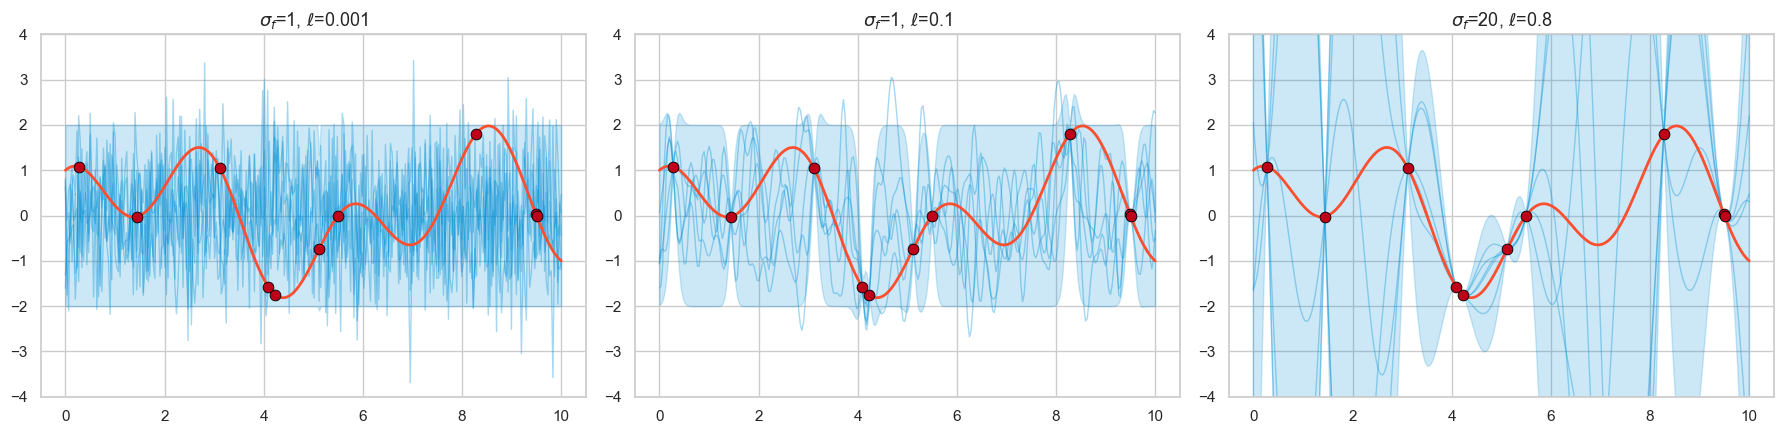

In [32]:
plot_posterior_grid([(1, .001), (1, .1), (20, .8)], n_samples=5)

## Scelta degli iperparametri: la verosimiglianza marginale

Come discusso nelle note, invece di scegliere gli iperparametri $\boldsymbol\theta=(\sigma_f,\ell,\sigma_n)$ a mano o mediante cross validation, li si può scegliere massimizzando la **verosimiglianza marginale** dei target osservati. Nel modello con rumore $\mathbf{t}\sim\mathcal{N}(\mathbf{0},\hat{\boldsymbol\Sigma}_{\mathbf{X}})$, e quindi
$$\log p(\mathbf{t}\mid\mathbf{X};\boldsymbol\theta)=\underbrace{-\frac12\mathbf{t}^T\hat{\boldsymbol\Sigma}_{\mathbf{X}}^{-1}\mathbf{t}}_{\text{adattamento ai dati}}\;\underbrace{-\;\frac12\log|\hat{\boldsymbol\Sigma}_{\mathbf{X}}|}_{\text{penalità di complessità}}\;-\;\frac n2\log(2\pi).$$
Il primo termine è grande quando i dati sono "spiegati" dalla covarianza del modello; il secondo è un termine di Occam, che penalizza i modelli flessibili, i quali distribuiscono la loro probabilità su moltissimi possibili vettori di target. Per mostrare questo compromesso servono dati un po' più numerosi: generiamo $40$ osservazioni rumorose della stessa funzione.

In [33]:
n_ml = 40
X_ml = np.sort(rng.uniform(0, 10, n_ml))
t_ml = f(X_ml) + rng.normal(0, sigma_n, n_ml)

def log_marginal_likelihood(X, t, sigma_f, l, sigma_n, terms=False):
    """Log verosimiglianza marginale di un GP con kernel RBF e rumore gaussiano."""
    K = kernel(X, X, sigma_f=sigma_f, l=l) + (sigma_n**2 + 1e-10)*np.eye(len(X))
    L = cholesky(K, lower=True)
    alpha = solve_triangular(L.T, solve_triangular(L, t, lower=True), lower=False)
    fit = -0.5 * t @ alpha
    complexity = -np.sum(np.log(np.diag(L)))          # = -1/2 log|K|
    const = -0.5 * len(X) * np.log(2*np.pi)
    return (fit, complexity, const) if terms else fit + complexity + const

I due termini al variare della length scale $\ell$, con $\sigma_f=1$ e $\sigma_n=0.2$ fissati. Per $\ell$ piccolo il modello è molto flessibile: si adatta bene ai dati (termine di adattamento alto) ma paga una forte penalità di complessità. Per $\ell$ grande il modello è troppo rigido per spiegare i dati, e il termine di adattamento crolla. La verosimiglianza marginale è massima per un valore intermedio di $\ell$, vicino a quello per cui le funzioni a priori hanno la stessa scala di variazione di $f$.

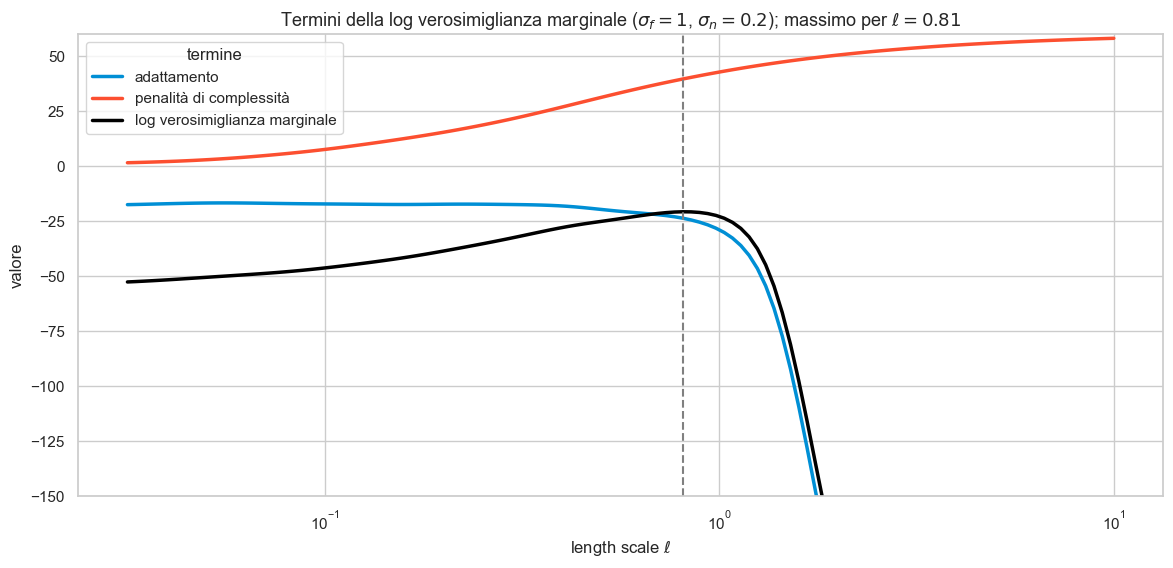

In [34]:
ls = np.logspace(-1.5, 1, 120)
terms = np.array([log_marginal_likelihood(X_ml, t_ml, 1., ll, sigma_n, terms=True) for ll in ls])
td = pd.DataFrame({'l': np.tile(ls, 3),
                   'valore': np.concatenate([terms[:,0], terms[:,1], terms.sum(1)]),
                   'termine': np.repeat(['adattamento', 'penalità di complessità', 'log verosimiglianza marginale'], len(ls))})
best_l = ls[np.argmax(terms.sum(1))]

fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=td, x='l', y='valore', hue='termine', palette=[colors[0], colors[1], 'black'], linewidth=2.5, ax=ax)
ax.axvline(best_l, color='grey', ls='--')
ax.set_xscale('log')
ax.set_ylim(-150, 60)
ax.set_xlabel(r'length scale $\ell$')
ax.set_title(r'Termini della log verosimiglianza marginale ($\sigma_f=1$, $\sigma_n={0}$); massimo per $\ell={1:.2f}$'.format(sigma_n, best_l))
plt.show()

La log verosimiglianza marginale su una griglia di valori di $\ell$ e $\sigma_n$ (con $\sigma_f=1$; i valori molto bassi sono troncati per leggibilità). Il massimo si trova vicino al valore vero del rumore ($\sigma_n=0.2$) e a una length scale intermedia. La forma della superficie mostra come i due iperparametri interagiscano nello spiegare i dati:

- con length scale grande e poco rumore (in basso a destra) la verosimiglianza è bassissima: una funzione molto liscia non può passare vicino a tutte le osservazioni, e un rumore piccolo non può spiegare le deviazioni;
- aumentando il rumore (verso l'alto) i dati diventano compatibili con qualunque length scale, perché le deviazioni vengono attribuite al rumore, ma la verosimiglianza diminuisce, perché un modello che prevede molto rumore distribuisce la probabilità su un insieme più ampio di possibili target;
- con length scale piccola e poco rumore (in basso a sinistra) il modello può interpolare i dati, ma paga la penalità di complessità.

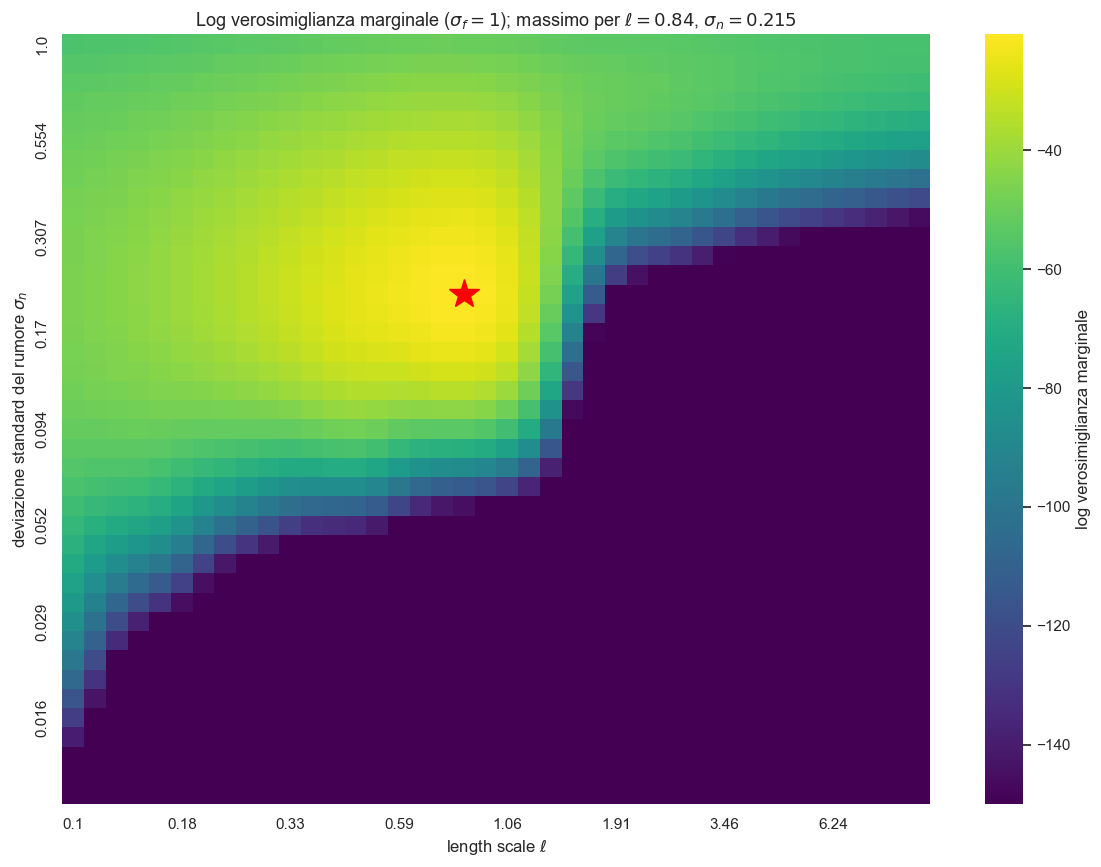

In [35]:
grid_l = np.logspace(-1, 1, 40)
grid_n = np.logspace(-2, 0, 40)
LML = np.array([[log_marginal_likelihood(X_ml, t_ml, 1., ll, sn) for ll in grid_l] for sn in grid_n])
lml_df = pd.DataFrame(np.maximum(LML, -150), index=np.round(grid_n, 3), columns=np.round(grid_l, 2))

plt.figure(figsize=(14, 10))
ax = sns.heatmap(lml_df[::-1], cmap='viridis', xticklabels=5, yticklabels=5, cbar_kws={'label': 'log verosimiglianza marginale'})
i, j = np.unravel_index(np.argmax(LML), LML.shape)
ax.plot(j + .5, len(grid_n) - i - .5, marker='*', color='red', ms=22)
ax.set_xlabel(r'length scale $\ell$')
ax.set_ylabel(r'deviazione standard del rumore $\sigma_n$')
ax.set_title(r'Log verosimiglianza marginale ($\sigma_f=1$); massimo per $\ell={0:.2f}$, $\sigma_n={1:.3f}$'.format(grid_l[j], grid_n[i]))
plt.show()

In pratica, la verosimiglianza marginale si massimizza rispetto a tutti gli iperparametri mediante metodi di ottimizzazione basati sul gradiente. Ottimizziamo rispetto ai **logaritmi** degli iperparametri: questi devono essere positivi, e il loro effetto dipende dall'ordine di grandezza. In generale la funzione può avere più massimi locali, ad esempio uno con length scale piccola e poco rumore e uno con length scale grande e molto rumore, e conviene ripetere l'ottimizzazione da più punti iniziali; in questo caso tutte le partenze convergono allo stesso massimo, con iperparametri vicini a quelli che hanno generato i dati.

In [36]:
def neg_lml(log_theta):
    sf, ll, sn = np.exp(log_theta)
    return -log_marginal_likelihood(X_ml, t_ml, sf, ll, sn)

best = None
for start in ([0., 0., -1.], [0., -1., -3.], [1., 1., 0.]):
    res = minimize(neg_lml, x0=start, method='L-BFGS-B')
    print('partenza {0}: sigma_f={1:.3f}, l={2:.3f}, sigma_n={3:.3f}, log ML={4:.3f}'.format(start, *np.exp(res.x), -res.fun))
    if best is None or res.fun < best.fun:
        best = res
sf_opt, l_opt, sn_opt = np.exp(best.x)

partenza [0.0, 0.0, -1.0]: sigma_f=1.237, l=0.893, sigma_n=0.215, log ML=-20.189
partenza [0.0, -1.0, -3.0]: sigma_f=1.237, l=0.893, sigma_n=0.215, log ML=-20.189
partenza [1.0, 1.0, 0.0]: sigma_f=1.237, l=0.893, sigma_n=0.215, log ML=-20.189


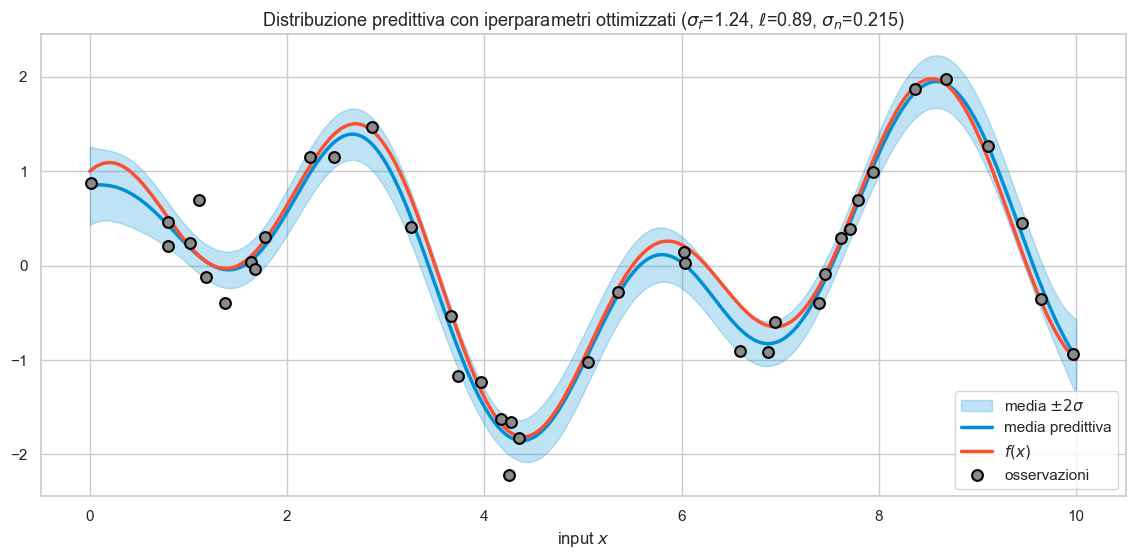

In [50]:
plot_predictive(X_test, X_ml, t_ml, r'Distribuzione predittiva con iperparametri ottimizzati ($\sigma_f$={0:.2f}, $\ell$={1:.2f}, $\sigma_n$={2:.3f})'.format(sf_opt, l_opt, sn_opt),
                sigma_f=sf_opt, l=l_opt, sigma_n=sn_opt, noise=True)

## La classe GaussianProcessRegressor di scikit-learn

scikit-learn implementa gli stessi calcoli nella classe `GaussianProcessRegressor`. Il kernel si costruisce componendo kernel elementari: `ConstantKernel` (un fattore costante, che corrisponde a $\sigma_f^2$), `RBF` (con la sua length scale) e `WhiteKernel` (che aggiunge $\sigma_n^2$ sulla diagonale, cioè il rumore, con un livello che può essere appreso). In alternativa il rumore si può specificare con l'argomento `alpha`, che aggiunge una costante fissa alla diagonale di $\mathbf{G}_{\mathbf{X}}$. Durante `fit` gli iperparametri del kernel sono scelti massimizzando la verosimiglianza marginale, a partire dai valori iniziali indicati e da `n_restarts_optimizer` punti iniziali casuali aggiuntivi.

Verifichiamo innanzitutto che, con gli stessi iperparametri e senza ottimizzazione (`optimizer=None`), scikit-learn produca gli stessi risultati della nostra implementazione.

In [51]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF, WhiteKernel

k = ConstantKernel(sf_opt**2) * RBF(length_scale=l_opt)
gpr = GaussianProcessRegressor(kernel=k, alpha=sn_opt**2, optimizer=None).fit(X_ml.reshape(-1, 1), t_ml)
m_sk, sd_sk = gpr.predict(X_test.reshape(-1, 1), return_std=True)
m_np, sd_np = predict(X_test, X_ml, t_ml, sigma_f=sf_opt, l=l_opt, sigma_n=sn_opt, noise=True)
print('differenza massima tra le medie: {0:.2e}'.format(np.abs(m_sk - m_np).max()))
print('differenza massima tra le deviazioni standard: {0:.2e}'.format(np.abs(sd_sk - sd_np).max()))
print('log verosimiglianza marginale: scikit-learn {0:.4f}, nostra implementazione {1:.4f}'.format(
    gpr.log_marginal_likelihood_value_, log_marginal_likelihood(X_ml, t_ml, sf_opt, l_opt, sn_opt)))

differenza massima tra le medie: 1.13e-10
differenza massima tra le deviazioni standard: 2.10e-10
log verosimiglianza marginale: scikit-learn -20.1892, nostra implementazione -20.1892


### Un esempio con più dati

Consideriamo ora una funzione più complessa, somma di tre sinusoidi,
$$f_0(x)=\sin(4\pi x)+\sin(7\pi x)+\sin(3\pi x),$$
osservata in $n=500$ punti di $[0,2]$ con rumore di deviazione standard $\sigma_n=0.4$. I punti di test si estendono fino a $2.5$, oltre l'intervallo dei dati, per osservare il comportamento in **estrapolazione**.

In [52]:
def f0(x):
    return np.sin(4*np.pi*x) + np.sin(7*np.pi*x) + np.sin(3*np.pi*x)

d = 1
n = 500
L = 2
x_ = np.linspace(start=0, stop=L, num=n)
X_ = x_.reshape(n, d)
sigma_n = 0.4
y_ = f0(x_) + rng.normal(loc=0, scale=sigma_n, size=n)

n_star = 650
x_star = np.linspace(start=0, stop=L+0.5, num=n_star)
X_star = x_star.reshape(n_star, d)

Definiamo il kernel $\sigma_f^2\,\mathrm{RBF}(\ell)+\sigma_n^2$, con tutti e tre gli iperparametri da apprendere, e i valori iniziali e gli intervalli di ricerca. A differenza del notebook originale, il livello del rumore non è fissato al valore vero ma appreso dai dati, tramite il `WhiteKernel`.

In [53]:
kernel_sk = ConstantKernel(constant_value=1, constant_value_bounds=(1e-2, 1e2)) \
            * RBF(length_scale=0.1, length_scale_bounds=(1e-2, 1e2)) \
            + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-4, 1e1))
gp = GaussianProcessRegressor(kernel=kernel_sk, n_restarts_optimizer=5, random_state=0)
gp.fit(X_, y_)
print('kernel appreso: {0}'.format(gp.kernel_))
print('sigma_n stimato: {0:.3f} (vero: {1})'.format(np.sqrt(gp.kernel_.k2.noise_level), sigma_n))
print('log verosimiglianza marginale: {0:.2f}'.format(gp.log_marginal_likelihood_value_))

kernel appreso: 1.81**2 * RBF(length_scale=0.104) + WhiteKernel(noise_level=0.154)
sigma_n stimato: 0.392 (vero: 0.4)
log verosimiglianza marginale: -301.66


Le predizioni si ottengono con `predict`, che con `return_std=True` restituisce anche la deviazione standard predittiva: non è quindi necessario stimarla da un campione di funzioni, come faceva il notebook originale generando $1300$ campioni di $1300$ valori. Si noti che, con il rumore modellato da un `WhiteKernel`, la deviazione standard restituita include anche il rumore: è quella di una nuova osservazione, non del valore di $f$. Per ottenere quest'ultima basta sottrarre $\sigma_n^2$ dalla varianza.

In [54]:
y_pred, y_std = gp.predict(X_star, return_std=True)
noise_var = gp.kernel_.k2.noise_level
f_std = np.sqrt(np.clip(y_std**2 - noise_var, 0, None))

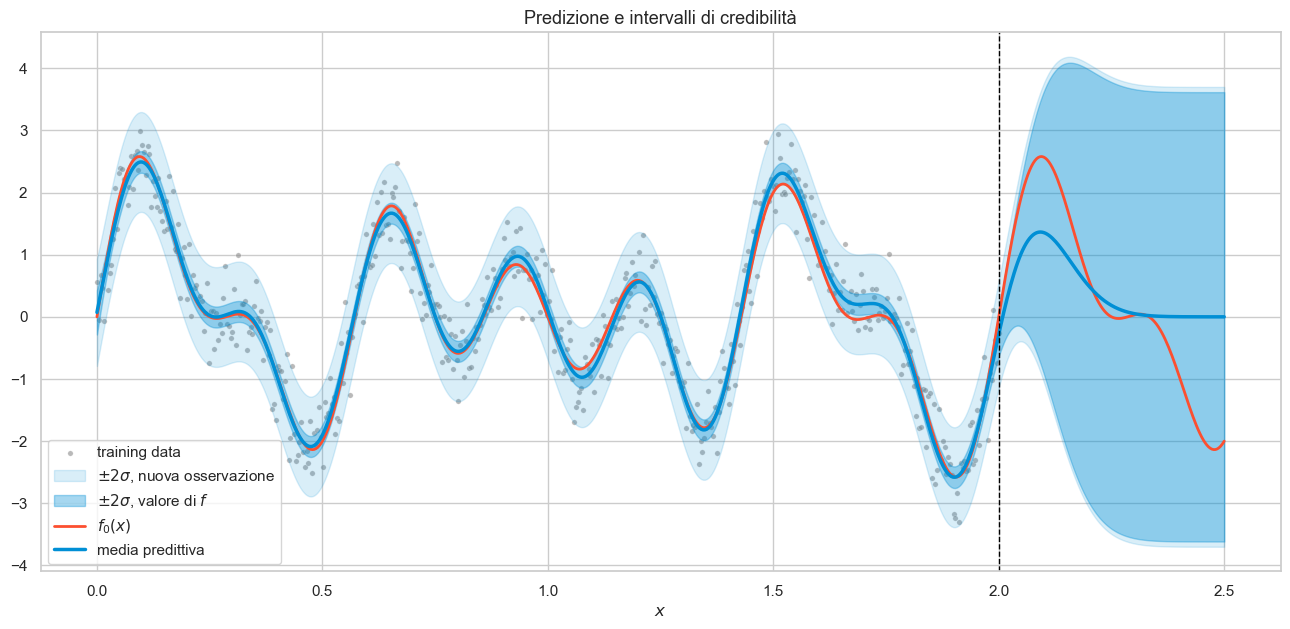

In [55]:
fig, ax = plt.subplots(figsize=(16, 7))
sns.scatterplot(x=x_, y=y_, color=colors[4], s=15, alpha=.6, label='training data', ax=ax)
ax.fill_between(x_star, y_pred - 2*y_std, y_pred + 2*y_std, color=colors[0], alpha=0.15, label=r'$\pm2\sigma$, nuova osservazione')
ax.fill_between(x_star, y_pred - 2*f_std, y_pred + 2*f_std, color=colors[0], alpha=0.35, label=r'$\pm2\sigma$, valore di $f$')
sns.lineplot(x=x_star, y=f0(x_star), color=colors[1], linewidth=2, label='$f_0(x)$', ax=ax)
sns.lineplot(x=x_star, y=y_pred, color=colors[0], linewidth=2.5, label='media predittiva', ax=ax)
ax.axvline(L, color='black', ls='--', lw=1)
ax.set(title='Predizione e intervalli di credibilità', xlabel='$x$')
ax.legend(loc='lower left')
plt.show()

Nell'intervallo dei dati la media predittiva segue bene la funzione, e la banda della funzione è stretta: con $500$ osservazioni l'incertezza epistemica è piccola, e la banda delle osservazioni è dominata dal rumore. Oltre $x=2$ (linea tratteggiata) il comportamento cambia completamente: il kernel RBF è **locale**, e allontanandosi dai dati di più di qualche length scale la media torna rapidamente alla media a priori, $0$, mentre l'incertezza cresce fino all'incertezza a priori $\sigma_f$. Il processo gaussiano "sa di non sapere", ma non può estrapolare la struttura periodica della funzione: per farlo occorrerebbe un kernel che la codifichi, come quello periodico (`ExpSineSquared`) che vedremo nell'altro notebook.